<a href="https://colab.research.google.com/github/Dheeraj-S-Pillai/Data-Analysis-using-python/blob/main/Module_End_Assignment_5_Data_Analysis_using_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

url = "https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/main/social_media_engagement_5000.csv"
df = pd.read_csv(url)
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [45]:
print("Data types before conversion:")
print(df.dtypes)

Data types before conversion:
user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object


In [46]:
df["posted_at"] = pd.to_datetime(df["posted_at"], format="%d-%m-%Y")
print("Data type of posted_at after conversion:", df["posted_at"].dtype)

Data type of posted_at after conversion: datetime64[ns]


In [47]:
impressions = np.array(df["impression_count"])
watch_times = np.array(df["watch_time_sec"])

print("Shape:", impressions.shape)
print("Total impressions:", impressions.sum())
print("Average impressions:", impressions.mean())
print("Maximum impressions:", impressions.max())
print("Minimum impressions:", impressions.min())
print("Posts with more than 50000 impressions:", (impressions > 50000).sum())
print("First 5 smallest impressions:", np.sort(impressions)[:5])
print("Average watch time in minutes:", watch_times.mean() / 60)

Shape: (5000,)
Total impressions: 250068664
Average impressions: 50013.7328
Maximum impressions: 99995
Minimum impressions: 105
Posts with more than 50000 impressions: 2496
First 5 smallest impressions: [105 111 113 115 147]
Average watch time in minutes: 66.90838666666667


# **Task** 2: Data Cleaning

##Cleaning Missing Data

In [48]:
print("Missing values in each column:")
print(df.isnull().sum())
print()
print("Total missing values:", df.isna().sum().sum())

Missing values in each column:
user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

Total missing values: 900


In [49]:
df["age"] = df["age"].fillna(df["age"].median())
df["likes"] = df["likes"].fillna(df["likes"].median())
df["comments"] = df["comments"].fillna(df["comments"].median())
df["shares"] = df["shares"].fillna(df["shares"].median())

df["gender"] = df["gender"].fillna(df["gender"].mode()[0])
df["sentiment"] = df["sentiment"].fillna(df["sentiment"].mode()[0])

print("Missing values after filling:")
print(df.isnull().sum())

Missing values after filling:
user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


### Duplicate Handling

In [50]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Shape after removing duplicates: (5000, 19)


### Data Formatting

In [51]:
df["age"] = df["age"].astype(int)
df["likes"] = df["likes"].astype(int)
df["comments"] = df["comments"].astype(int)
df["shares"] = df["shares"].astype(int)

df["gender"] = df["gender"].str.strip().str.title()
df["sentiment"] = df["sentiment"].str.strip().str.lower()
df["country"] = df["country"].str.strip()
df["post_type"] = df["post_type"].str.strip().str.lower()
df["post_category"] = df["post_category"].str.strip().str.lower()
df["device_type"] = df["device_type"].str.strip().str.lower()

print(df["gender"].value_counts())
print()
print(df["sentiment"].value_counts())

gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64


In [52]:
rows_before = df.shape[0]
df = df[(df["likes"] + df["comments"] + df["shares"]) <= df["impression_count"]]
df = df.reset_index(drop=True)

print("Rows before:", rows_before)
print("Rows after removing unrealistic engagement:", df.shape[0])
print("Rows removed:", rows_before - df.shape[0])
print("Highest engagement rate now:", df["engagement_rate"].max())

Rows before: 5000
Rows after removing unrealistic engagement: 4400
Rows removed: 600
Highest engagement rate now: 1.359438632


### Feature Cleaning

In [53]:
df["hashtag_count"] = df["hashtags"].str.split().str.len()
print(df[["hashtags", "hashtag_count"]].head())
print()
print(df["hashtag_count"].value_counts())

                hashtags  hashtag_count
0  #foodie #travel #love              3
1               #fitness              1
2                #foodie              1
3    #music #foodie #fun              3
4               #fitness              1

hashtag_count
2    1501
3    1452
1    1447
Name: count, dtype: int64


## Task 3: Data Exploration using Pandas

In [54]:
print("First 5 rows:")
print(df.head())
print()
print("Last 5 rows:")
print(df.tail())
print()
print("Shape:", df.shape)
print()
print("Columns:", list(df.columns))

First 5 rows:
   user_id  age  gender country  post_id post_type post_category  likes  \
0    25795   43  Female  Brazil   496713     image       fitness   7011   
1    10860   33    Male  Brazil   157326      reel          food  11750   
2    86820   32  Female      UK   109864      text          food   4862   
3    64886   51   Other  France   848877      text       fitness   5350   
4    92386   16   Other  Canada   174310     video          tech  12535   

   comments  shares  watch_time_sec  impression_count  posted_at  \
0       354    1157            5726             44650 2022-12-17   
1      2606    1807            5947             80216 2023-06-02   
2       344     955            6946             44858 2023-05-07   
3      1083    1049             229             70455 2023-02-12   
4      1790      99            1427             24893 2023-09-16   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      mobile  neg

In [55]:
df.info()
print()
print(df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4400 entries, 0 to 4399
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           4400 non-null   int64         
 1   age               4400 non-null   int64         
 2   gender            4400 non-null   object        
 3   country           4400 non-null   object        
 4   post_id           4400 non-null   int64         
 5   post_type         4400 non-null   object        
 6   post_category     4400 non-null   object        
 7   likes             4400 non-null   int64         
 8   comments          4400 non-null   int64         
 9   shares            4400 non-null   int64         
 10  watch_time_sec    4400 non-null   int64         
 11  impression_count  4400 non-null   int64         
 12  posted_at         4400 non-null   datetime64[ns]
 13  follower_count    4400 non-null   int64         
 14  is_verified       4400 n

In [56]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,4400.000000,4400.000000,4400.000000,4400.000000,4400.000000,4400.000000,4400.000000,4400.000000,4400,4400.000000,4400.000000,4400.000000
mean,54410.334545,38.462273,546851.392500,9748.795455,1491.487045,996.127955,3990.642955,55787.921818,2022-12-27 10:29:20.727272704,394358.252500,0.285955,2.001136
min,10055.000000,13.000000,100184.000000,10.000000,0.000000,0.000000,0.000000,2190.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32178.250000,26.000000,320398.500000,4841.000000,783.750000,505.000000,1973.000000,33520.750000,2022-07-02 00:00:00,194247.250000,0.133626,1.000000
50%,54056.500000,38.000000,545621.000000,9880.500000,1497.000000,1012.000000,3996.000000,55561.000000,2022-12-25 00:00:00,390844.000000,0.225688,2.000000
75%,77034.500000,51.000000,770795.000000,14475.000000,2230.000000,1471.250000,6008.000000,78177.750000,2023-06-26 00:00:00,590131.000000,0.370058,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,1.359439,3.000000
std,26085.554185,14.712458,261021.729133,5679.706608,856.205310,570.436724,2312.625203,25764.626479,NaN,230742.618541,0.211538,0.811796


In [57]:
category_columns = ["gender", "country", "post_type", "post_category", "device_type", "sentiment"]

for col in category_columns:
    print(col)
    print(df[col].value_counts())
    print()

gender
gender
Male      1619
Other     1398
Female    1383
Name: count, dtype: int64

country
country
India        491
Canada       455
USA          444
UK           444
Brazil       440
Germany      440
UAE          434
France       428
Australia    416
Japan        408
Name: count, dtype: int64

post_type
post_type
reel     1143
image    1102
text     1087
video    1068
Name: count, dtype: int64

post_category
post_category
tech         585
fitness      574
education    558
music        558
lifestyle    534
food         531
fashion      531
travel       529
Name: count, dtype: int64

device_type
device_type
mobile     1475
desktop    1472
tablet     1453
Name: count, dtype: int64

sentiment
sentiment
positive    2229
neutral     1341
negative     830
Name: count, dtype: int64



In [58]:
print("Unique countries:", df["country"].unique())
print("Unique post types:", df["post_type"].unique())
print("Unique sentiments:", df["sentiment"].unique())
print()
print("Number of unique values in each column:")
print(df.nunique())

Unique countries: ['Brazil' 'UK' 'France' 'Canada' 'Japan' 'Australia' 'India' 'UAE'
 'Germany' 'USA']
Unique post types: ['image' 'reel' 'text' 'video']
Unique sentiments: ['negative' 'positive' 'neutral']

Number of unique values in each column:
user_id             4293
age                   52
gender                 3
country               10
post_id             4393
post_type              4
post_category          8
likes               3817
comments            2267
shares              1760
watch_time_sec      3357
impression_count    4292
posted_at            729
follower_count      4386
is_verified            2
device_type            3
sentiment              3
hashtags             726
engagement_rate     4400
hashtag_count          3
dtype: int64


In [59]:
numeric_columns = ["age", "likes", "comments", "shares", "watch_time_sec",
                   "impression_count", "follower_count", "engagement_rate", "hashtag_count"]

corr = df[numeric_columns].corr()
corr

,age,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
age,1.000000,-0.035897,-0.012354,0.005295,0.003975,0.013945,-0.014704,-0.033975,0.010558
likes,-0.035897,1.000000,-0.019289,0.007802,0.011239,0.117421,-0.026863,0.432481,-0.001535
comments,-0.012354,-0.019289,1.000000,0.004869,-0.019171,0.007873,-0.003873,0.063805,-0.010828
shares,0.005295,0.007802,0.004869,1.000000,0.016459,0.015665,-0.006140,0.044779,0.023082
watch_time_sec,0.003975,0.011239,-0.019171,0.016459,1.000000,0.014522,-0.005604,-0.011196,-0.024090
impression_count,0.013945,0.117421,0.007873,0.015665,0.014522,1.000000,-0.024023,-0.682349,-0.008733
follower_count,-0.014704,-0.026863,-0.003873,-0.006140,-0.005604,-0.024023,1.000000,0.004559,0.008991
engagement_rate,-0.033975,0.432481,0.063805,0.044779,-0.011196,-0.682349,0.004559,1.000000,-0.003272
hashtag_count,0.010558,-0.001535,-0.010828,0.023082,-0.024090,-0.008733,0.008991,-0.003272,1.000000


In [60]:
print("Average likes by post type:")
print(df.groupby("post_type")["likes"].mean())
print()
print("Average impressions by country:")
print(df.groupby("country")["impression_count"].mean())

Average likes by post type:
post_type
image    9727.195100
reel     9713.684164
text     9723.519779
video    9834.385768
Name: likes, dtype: float64

Average impressions by country:
country
Australia    56071.706731
Brazil       55078.795455
Canada       54012.424176
France       58749.992991
Germany      53214.365909
India        56478.248473
Japan        56122.156863
UAE          55567.937788
UK           55930.653153
USA          56741.058559
Name: impression_count, dtype: float64


## Task 4: Data Wrangling

In [61]:
country_info = pd.DataFrame({
    "country": ["India", "Canada", "Brazil", "UAE", "USA", "France", "UK", "Australia", "Germany", "Japan"],
    "continent": ["Asia", "North America", "South America", "Asia", "North America",
                  "Europe", "Europe", "Oceania", "Europe", "Asia"]
})

df = pd.merge(df, country_info, on="country", how="left")
df[["country", "continent"]].head()

,country,continent
0,Brazil,South America
1,Brazil,South America
2,UK,Europe
3,France,Europe
4,Canada,North America


In [62]:
top_posts = df.sort_values("likes", ascending=False).head(5)
low_posts = df.sort_values("likes", ascending=True).head(5)

combined = pd.concat([top_posts, low_posts])
combined[["post_id", "post_type", "likes", "impression_count"]]

,post_id,post_type,likes,impression_count
3514,850959,text,19998,44044
1367,753479,image,19996,65650
1325,589982,video,19995,63736
245,938147,reel,19994,42890
2126,771366,text,19992,57469
2987,274060,reel,10,79771
2034,190214,video,18,37312
2545,789186,reel,25,48082
3562,747377,video,26,94797
3351,712274,video,27,81086


In [63]:
df["engagement_score"] = df["likes"] + df["comments"] + df["shares"]
df["log_likes"] = np.log1p(df["likes"])

df[["likes", "comments", "shares", "engagement_score", "log_likes", "hashtag_count"]].head()

,likes,comments,shares,engagement_score,log_likes,hashtag_count
0,7011,354,1157,8522,8.855378,3
1,11750,2606,1807,16163,9.371694,1
2,4862,344,955,6161,8.489411,1
3,5350,1083,1049,7482,8.585039,3
4,12535,1790,99,14424,9.436360,1


In [64]:
print("Summary by post type:")
print(df.groupby("post_type")[["engagement_score", "engagement_rate", "impression_count"]].mean())
print()
print("Summary by country:")
print(df.groupby("country")[["engagement_score", "engagement_rate", "impression_count"]].mean())
print()
print("Summary by sentiment:")
print(df.groupby("sentiment")[["engagement_score", "engagement_rate", "impression_count"]].mean())

Summary by post type:
           engagement_score  engagement_rate  impression_count
post_type                                                     
image          12265.984574         0.292175      55260.081670
reel           12177.159230         0.281681      55632.332458
text           12218.173873         0.285759      56140.666053
video          12287.867978         0.284312      56140.061798

Summary by country:
           engagement_score  engagement_rate  impression_count
country                                                       
Australia      12491.117788         0.282379      56071.706731
Brazil         11930.297727         0.285398      55078.795455
Canada         12317.054945         0.298327      54012.424176
France         12455.665888         0.266819      58749.992991
Germany        12372.979545         0.310031      53214.365909
India          12213.482688         0.281589      56478.248473
Japan          12175.100490         0.288057      56122.156863
UAE         

## Task 5: Statistical Analysis

In [65]:
stats_columns = ["likes", "comments", "shares", "watch_time_sec", "engagement_rate", "follower_count"]

for col in stats_columns:
    print(col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Standard deviation:", df[col].std())
    print("Variance:", df[col].var())
    print("25th percentile:", df[col].quantile(0.25))
    print("75th percentile:", df[col].quantile(0.75))
    print("90th percentile:", df[col].quantile(0.90))
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())
    print()

likes
Mean: 9748.795454545454
Median: 9880.5
Mode: 10105
Standard deviation: 5679.706607640628
Variance: 32259067.148876607
25th percentile: 4841.0
75th percentile: 14475.0
90th percentile: 17728.7
Skewness: 0.0629231610065228
Kurtosis: -1.134892298661692

comments
Mean: 1491.4870454545455
Median: 1497.0
Mode: 1497
Standard deviation: 856.2053097553118
Variance: 733087.5324531894
25th percentile: 783.75
75th percentile: 2230.0
90th percentile: 2680.0
Skewness: 0.008247172911891353
Kurtosis: -1.147944760415647

shares
Mean: 996.1279545454546
Median: 1012.0
Mode: 1012
Standard deviation: 570.4367244445625
Variance: 325398.0565950417
25th percentile: 505.0
75th percentile: 1471.25
90th percentile: 1787.1
Skewness: -0.010688528952855214
Kurtosis: -1.147993587764281

watch_time_sec
Mean: 3990.6429545454544
Median: 3996.0
Mode: 916
Standard deviation: 2312.62520267501
Variance: 5348235.328047631
25th percentile: 1973.0
75th percentile: 6008.0
90th percentile: 7214.0
Skewness: -0.003063109089

## Task 6: Data Visualization

### Matplotlib

#### Scatter plot: likes vs impressions

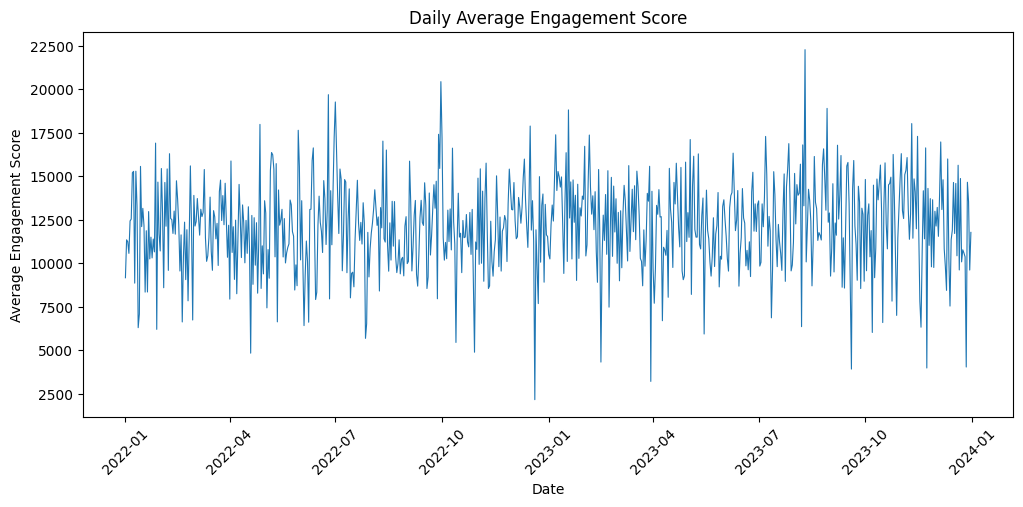

In [66]:
daily = df.groupby("posted_at")["engagement_score"].mean()

plt.figure(figsize=(12, 5))
plt.plot(daily.index, daily.values, linewidth=0.8)
plt.title("Daily Average Engagement Score")
plt.xlabel("Date")
plt.ylabel("Average Engagement Score")
plt.xticks(rotation=45)
plt.show()

#### Bar chart: posts by category


#### Pie chart: gender distribution

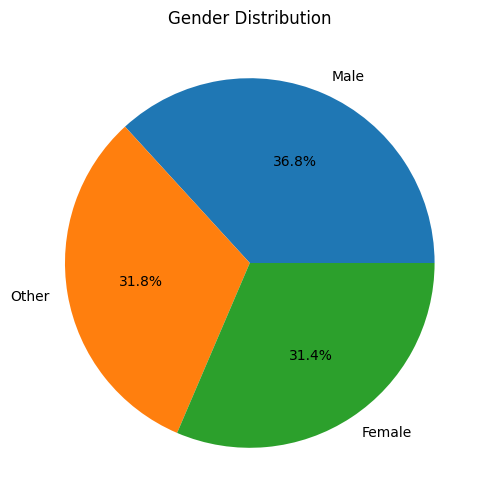

In [67]:
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(gender_counts.values, labels=gender_counts.index, autopct="%1.1f%%")
plt.title("Gender Distribution")
plt.show()

#### Histogram: age

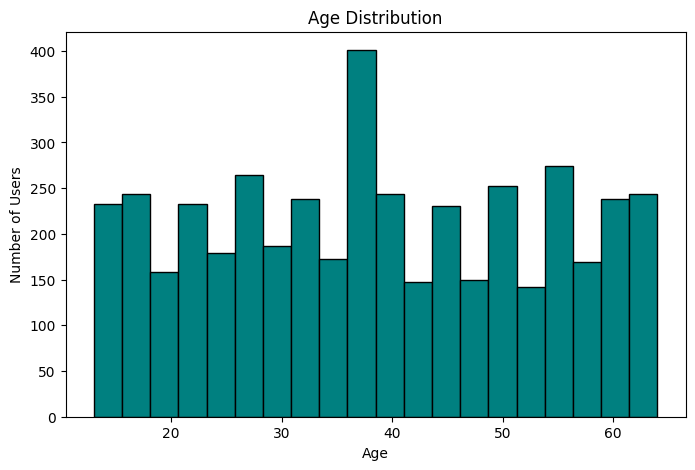

In [68]:
plt.figure(figsize=(8, 5))
plt.hist(df["age"], bins=20, color="teal", edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Users")
plt.show()

#### Box plot: engagement rate

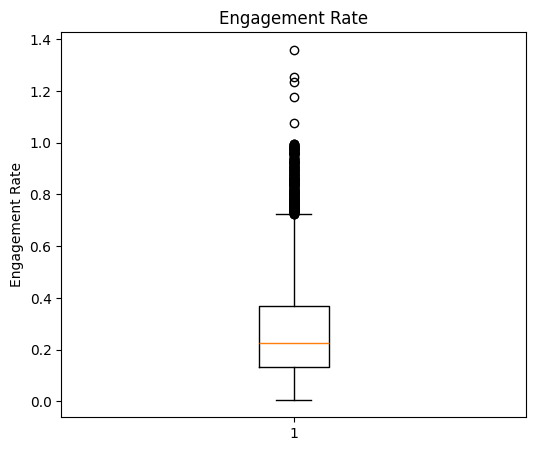

In [69]:
plt.figure(figsize=(6, 5))
plt.boxplot(df["engagement_rate"])
plt.title("Engagement Rate")
plt.ylabel("Engagement Rate")
plt.show()

### Seaborn

#### Count plot: post type

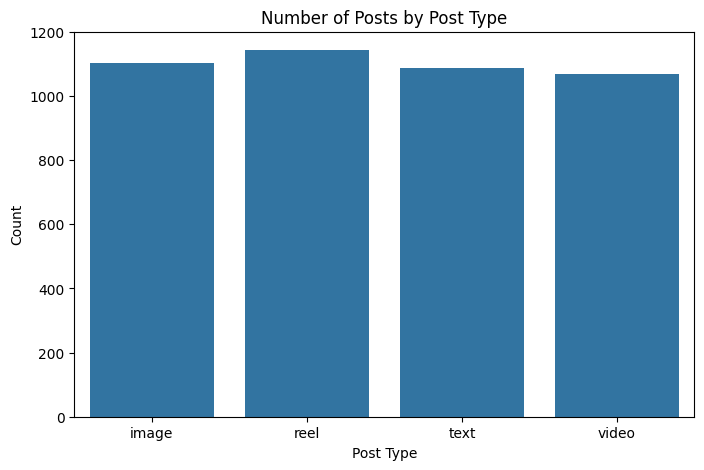

In [70]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="post_type")
plt.title("Number of Posts by Post Type")
plt.xlabel("Post Type")
plt.ylabel("Count")
plt.show()

#### Bar plot: average likes by category

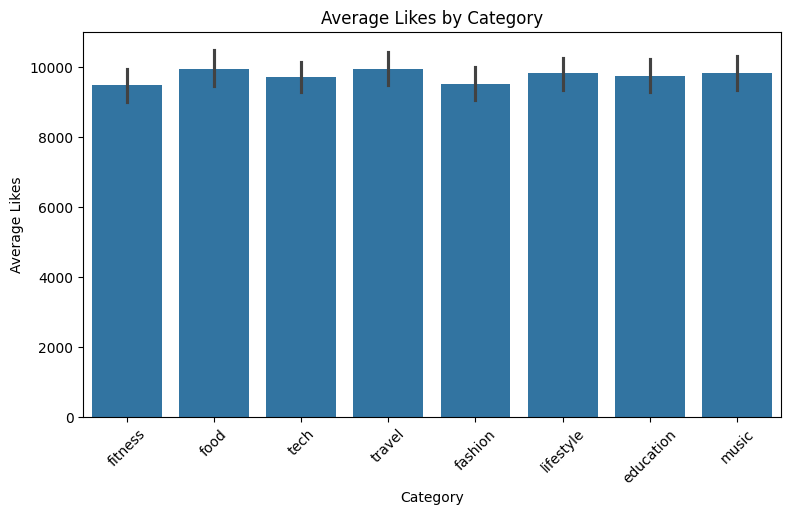

In [71]:
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x="post_category", y="likes")
plt.title("Average Likes by Category")
plt.xlabel("Category")
plt.ylabel("Average Likes")
plt.xticks(rotation=45)
plt.show()

#### Violin plot: followers vs sentiment

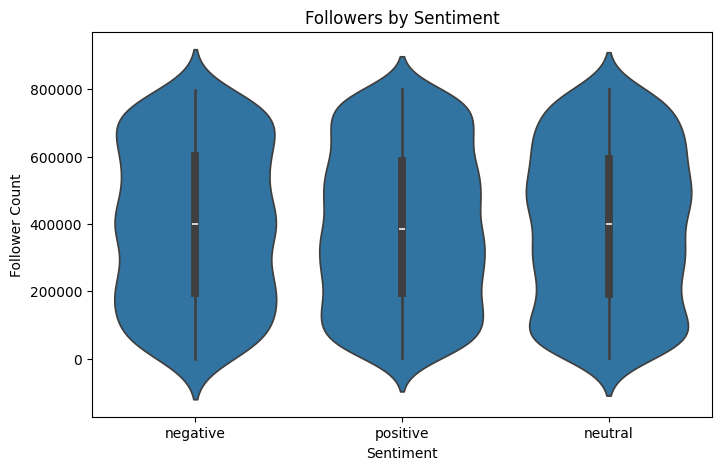

In [72]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="sentiment", y="follower_count")
plt.title("Followers by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Follower Count")
plt.show()

#### Pair plot: numeric features

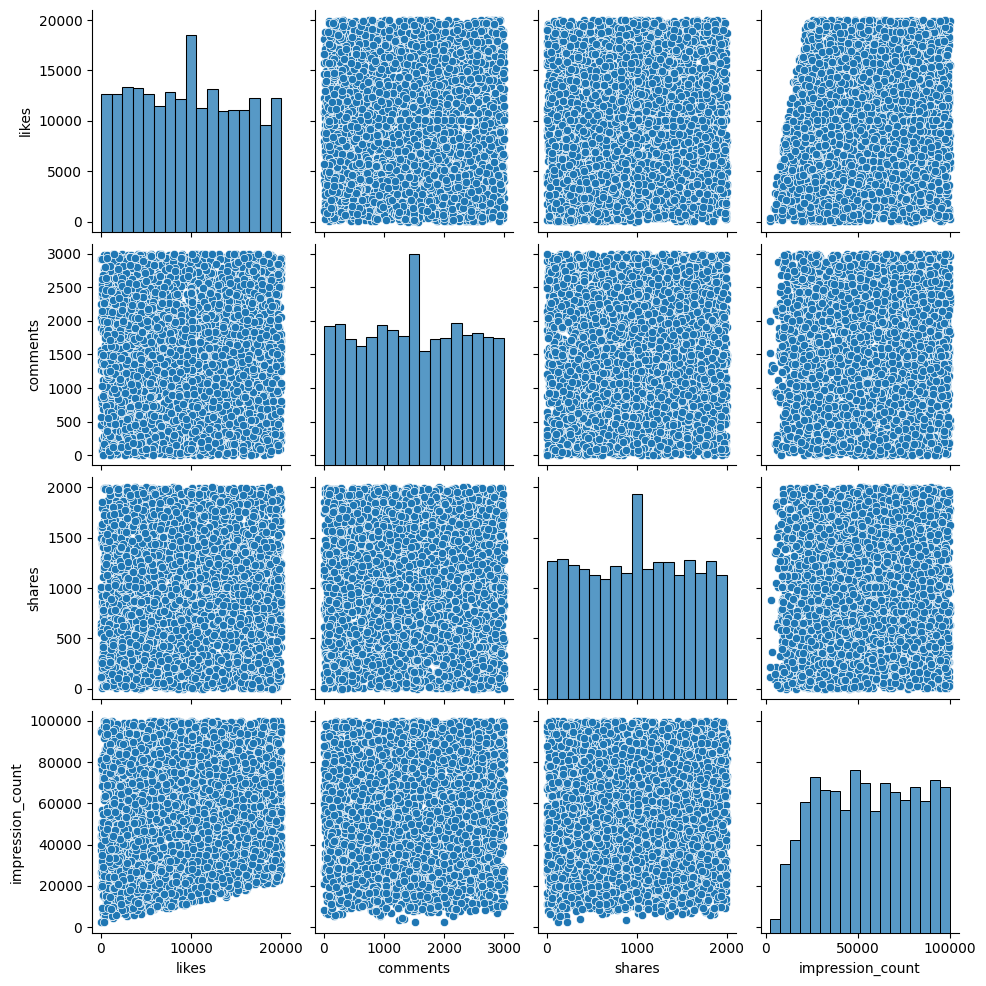

In [73]:
sns.pairplot(df[["likes", "comments", "shares", "impression_count"]])
plt.show()

#### Heatmap: correlation matrix

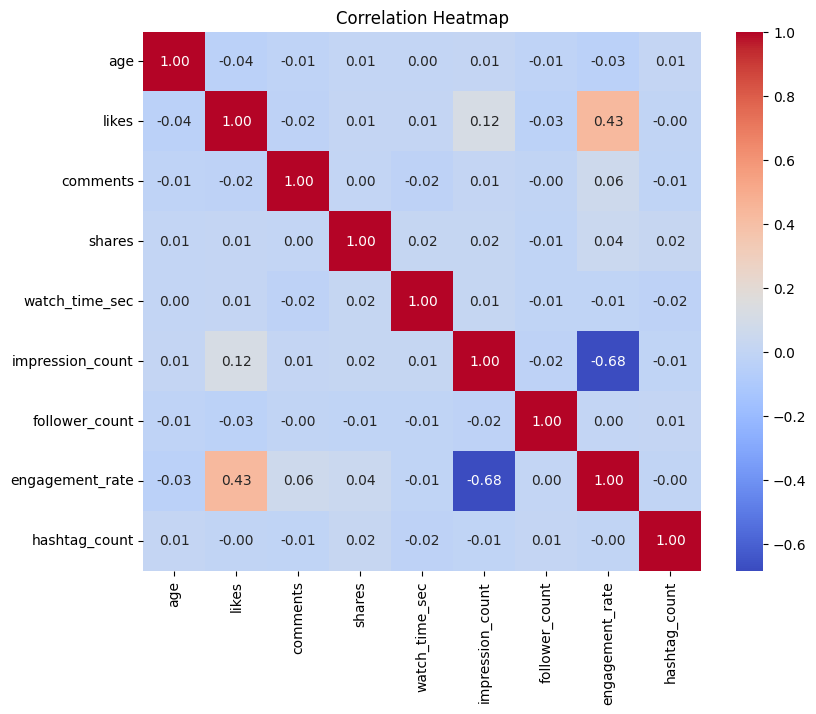

In [74]:
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

#### Swarm plot: engagement vs device

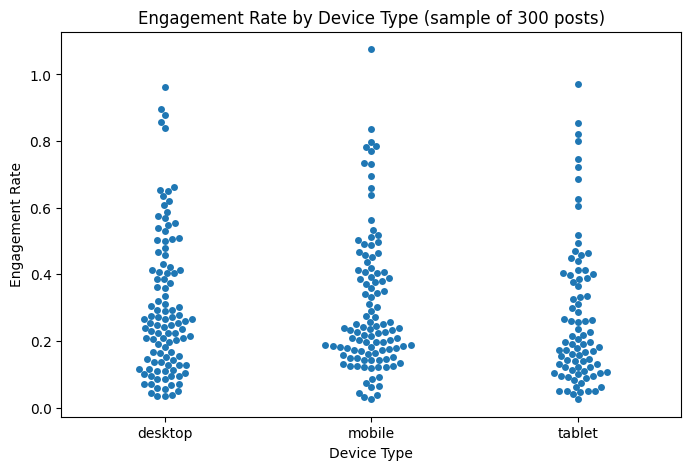

In [75]:
sample = df.sample(300, random_state=1)

plt.figure(figsize=(8, 5))
sns.swarmplot(data=sample, x="device_type", y="engagement_rate")
plt.title("Engagement Rate by Device Type (sample of 300 posts)")
plt.xlabel("Device Type")
plt.ylabel("Engagement Rate")
plt.show()

### Plotly (Interactive)

#### Bar chart: average engagement score by post type

In [76]:
type_scores = df.groupby("post_type")["engagement_score"].mean().reset_index()

fig = px.bar(type_scores, x="post_type", y="engagement_score",
             title="Average Engagement Score by Post Type")
fig.show()

#### Line chart: daily engagement trend

In [77]:
daily_df = df.groupby("posted_at")["engagement_score"].mean().reset_index()

fig = px.line(daily_df, x="posted_at", y="engagement_score",
              title="Daily Average Engagement Score")
fig.show()

#### Bubble chart: likes vs impressions

In [78]:
bubble_sample = df.sample(500, random_state=1)

fig = px.scatter(bubble_sample, x="impression_count", y="likes",
                 size="comments", color="post_type",
                 title="Likes vs Impressions (sample of 500 posts)")
fig.show()

## Final Insights

### Content Performance

In [79]:
type_engagement = df.groupby("post_type")["engagement_score"].mean().sort_values(ascending=False)
print("Average engagement score by post type:")
print(type_engagement)
print("Highest engagement post type:", type_engagement.idxmax())

Average engagement score by post type:
post_type
video    12287.867978
image    12265.984574
text     12218.173873
reel     12177.159230
Name: engagement_score, dtype: float64
Highest engagement post type: video


In [80]:
category_engagement = df.groupby("post_category")["engagement_score"].mean().sort_values(ascending=False)
print("Average engagement score by category:")
print(category_engagement)
print("Best performing category:", category_engagement.idxmax())

Average engagement score by category:
post_category
food         12431.338983
music        12396.050179
travel       12356.705104
lifestyle    12280.539326
tech         12229.094017
education    12179.618280
fashion      12029.137476
fitness      12003.388502
Name: engagement_score, dtype: float64
Best performing category: food


In [81]:
country_engagement = df.groupby("country")["engagement_rate"].mean().sort_values(ascending=False)
print("Average engagement rate by country:")
print(country_engagement)
print("Country with highest engagement rate:", country_engagement.idxmax())

Average engagement rate by country:
country
Germany      0.310031
Canada       0.298327
Japan        0.288057
Brazil       0.285398
UAE          0.284815
UK           0.284691
Australia    0.282379
India        0.281589
USA          0.277046
France       0.266819
Name: engagement_rate, dtype: float64
Country with highest engagement rate: Germany


### User Trends

In [82]:
df["age_group"] = pd.cut(df["age"], bins=[12, 20, 30, 40, 50, 65],
                         labels=["13-20", "21-30", "31-40", "41-50", "51-64"])

age_engagement = df.groupby("age_group", observed=True)[["engagement_score", "engagement_rate"]].mean()
print("Engagement by age group:")
print(age_engagement)
print()
print("Correlation of age with engagement rate:", df["age"].corr(df["engagement_rate"]))
print("Correlation of age with engagement score:", df["age"].corr(df["engagement_score"]))

Engagement by age group:
           engagement_score  engagement_rate
age_group                                   
13-20          12487.289764         0.299478
21-30          12294.319815         0.288036
31-40          12544.821281         0.288157
41-50          12220.639429         0.282452
51-64          11810.214101         0.277518

Correlation of age with engagement rate: -0.03397482746255848
Correlation of age with engagement score: -0.03670441783773522


In [83]:
verified_engagement = df.groupby("is_verified")[["engagement_score", "engagement_rate", "likes", "follower_count"]].mean()
print("Verified vs not verified accounts:")
print(verified_engagement)

Verified vs not verified accounts:
             engagement_score  engagement_rate        likes  follower_count
is_verified                                                                
False            12279.638169         0.289012  9791.840583   395691.071662
True             11829.988180         0.257220  9344.089835   381827.231678


### Behavioral Insights

In [84]:
df["weekday"] = df["posted_at"].dt.day_name()
df["month"] = df["posted_at"].dt.month_name()

weekday_impressions = df.groupby("weekday")["impression_count"].mean().sort_values(ascending=False)
print("Average impressions by day of week:")
print(weekday_impressions)
print("Best day for impressions:", weekday_impressions.idxmax())
print()

month_impressions = df.groupby("month")["impression_count"].mean().sort_values(ascending=False)
print("Average impressions by month:")
print(month_impressions)
print("Best month for impressions:", month_impressions.idxmax())

Average impressions by day of week:
weekday
Saturday     56801.551343
Tuesday      56715.243451
Sunday       56183.053042
Wednesday    56173.517241
Monday       55598.735818
Friday       54921.239502
Thursday     54048.511513
Name: impression_count, dtype: float64
Best day for impressions: Saturday

Average impressions by month:
month
October      57418.886792
September    56774.140541
January      56649.094241
February     56481.729345
May          56346.628319
November     56297.217984
August       56234.223587
March        55576.328612
December     55380.643275
April        54679.354054
June         53977.606383
July         53649.182796
Name: impression_count, dtype: float64
Best month for impressions: October


In [85]:
device_watch = df.groupby("device_type")["watch_time_sec"].mean().sort_values(ascending=False)
print("Average watch time (seconds) by device type:")
print(device_watch)
print("Device with highest watch time:", device_watch.idxmax())

Average watch time (seconds) by device type:
device_type
mobile     4078.126780
tablet     3964.189264
desktop    3929.093071
Name: watch_time_sec, dtype: float64
Device with highest watch time: mobile


### Sentiment Analysis

In [86]:
sentiment_engagement = df.groupby("sentiment")[["engagement_score", "engagement_rate", "likes",
                                                "comments", "shares", "watch_time_sec"]].mean()
print("Average metrics by sentiment:")
print(sentiment_engagement)
print()
print("Sentiment with highest engagement score:", sentiment_engagement["engagement_score"].idxmax())
print()
print("Number of posts by sentiment:")
print(df["sentiment"].value_counts())

Average metrics by sentiment:
           engagement_score  engagement_rate        likes     comments  \
sentiment                                                                
negative       12291.012048         0.277250  9776.760241  1514.800000   
neutral        12040.506339         0.287842  9525.172260  1521.520507   
positive       12333.937640         0.288062  9872.917452  1464.737550   

               shares  watch_time_sec  
sentiment                              
negative   999.451807     4016.674699  
neutral    993.813572     4000.074571  
positive   996.282638     3975.275460  

Sentiment with highest engagement score: positive

Number of posts by sentiment:
sentiment
positive    2229
neutral     1341
negative     830
Name: count, dtype: int64


## Summary of Findings

**Content performance**
- Video posts have the highest average engagement score (about 12,288), but all four post types are within 1% of each other.
- Food is the best-performing category (about 12,431) and fitness is the lowest (about 12,003).
- Germany has the highest average engagement rate (0.310) and France the lowest (0.267).

**User trends**
- Engagement falls slightly with age. The 51-64 group is lowest, and the correlation between age and engagement rate is very weak (-0.03).
- Verified accounts do not perform better. Their engagement score (about 11,830) and engagement rate (0.257) are lower than for unverified accounts (about 12,280 and 0.289).

**Behavioral insights**
- The dataset has only dates and no clock time, so best time of day cannot be measured. By day of week, Saturday has the highest average impressions, and by month, October does.
- Mobile users have the highest average watch time (about 4,078 seconds), followed by tablet and desktop.

**Sentiment**
- Positive posts have the highest engagement score (about 12,334). Neutral posts are lowest (about 12,041).
- Negative posts perform about as well as positive ones, with an engagement score of about 12,291, and they make up the smallest share of posts (830 of 4,400).

**Data notes**
- 150 missing values in each of age, gender, likes, comments, shares and sentiment were filled with the median (numbers) or mode (text).
- 600 posts where likes + comments + shares was greater than impressions were removed as unrealistic, leaving 4,400 rows.
- Differences between groups are small throughout, so these results show weak patterns, not strong effects.
